# Week 5 — Master summary, provenance ledger, and claim audit

**Purpose.** This notebook computes no new physics. It assembles the results of notebooks 01–04
into (a) a single comparison table, (b) a **provenance ledger** binding every headline number to
the file and filter that produced it, (c) the four-panel summary figure, and (d) an automated
**audit of superseded numbers still present in `README.md` and `docs/`**.

**Why a ledger.** The project convention (`CLAUDE.md`, *Writing about results*) is that every claim
in `docs/` and `paper/` must be traceable to a CSV in `data/`, named together with the filter that
produced it. §2 makes that machine-checkable rather than a matter of discipline.

**Why an audit.** Notebooks 03 and 04 superseded six headline numbers between them. Those numbers
are still quoted in `README.md` and `docs/`. §4 locates every surviving instance so none is missed.

---

### What a reader needs to know before quoting any number

1. **Both architectures' "best $T_2$" headline numbers are grid-edge artefacts.** The transmon's
   187 µs sits at $E_J{=}3.0$, $E_C{=}0.10$ — *both* grid edges — at $f_{01} = 1.45$ GHz, outside
   the 3–6 GHz band real transmons occupy. The fluxonium's unconstrained maximum of 5427 µs
   (reported in earlier versions as 5578 µs, its first-order-only value) sits at $E_J{=}15$,
   $E_L{=}0.2$ — also both grid edges — at 75 MHz with $\bar n_{\rm th} = 3.7$. **Neither is a design
   recommendation**, and the symmetry is not a coincidence: in both planes $T_2$ correlates with
   $f_{01}$ at $|r| > 0.99$, so a raw $T_2$ maximum is a frequency minimum wearing a disguise.

2. **The frequency-constrained numbers are the quotable ones**, and they are given here alongside
   the constraint that produced them.

3. **Q3 has no single answer.** The fluxonium/transmon ratio is $18\times$, $\sim\!1\times$, or
   $\sim\!500\times$ depending on the metric. §1 reports all of them; §5 states what may and may
   not be claimed.

In [1]:
# --- project bootstrap: run from anywhere, keeps data/ and figures/ paths working ---
import os, sys
from pathlib import Path
_here = Path.cwd()
if _here.name == "notebooks":          # notebook lives in notebooks/, project root is one level up
    os.chdir(_here.parent)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))  # makes `from coherence import ...` available
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("project root:", ROOT.name)          # name only; the absolute path is machine-specific

project root: quantum-coherence-sweet-spots-transmon-fluxonium


## 0. Artefact inventory and consistency check

Every input is a committed artefact of an upstream notebook. Three checks run before anything is
summarised:

**Inventory.** Every file this notebook reads is listed with its size and modification time, so a
stale artefact is visible rather than silently summarised.

**Noise-amplitude agreement.** Each upstream metadata file records the amplitudes in force when it
was written. If any disagrees with the current `DEFAULTS`, the artefacts are mutually incompatible
and the summary would be mixing runs.

**Anchor re-verification.** The two operating-point $T_2$ values are recomputed from
`src/coherence.py` and asserted against what notebook 04 recorded. This is the one place the
summary touches the physics, and it exists so that a summary can never quietly disagree with the
pipeline it summarises.

In [2]:
import json, platform
from datetime import datetime

import numpy as np
import pandas as pd
import scqubits as scq
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from qubits import make_transmon, make_fluxonium, anharmonicity, FLUXONIUM_DEFAULTS
from coherence import (transmon_coherence, fluxonium_coherence, n_thermal,
                       git_revision, noise_param_snapshot, DEFAULTS)
import plotting as pl

scq.settings.T1_DEFAULT_WARNING = False
NOISE_PARAMS_SNAPSHOT = noise_param_snapshot()

PROVENANCE = {
    "date": datetime.now().isoformat(timespec="seconds"),
    "git_revision": git_revision(),
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "scqubits": scq.__version__,
    "platform": platform.platform(),
    "noise_amplitudes": {k: DEFAULTS[k] for k in ("Q_cap", "A_ng", "A_flux", "A_cc")},
    "scqubits_noise_params": NOISE_PARAMS_SNAPSHOT,
    "units": "frequencies GHz; coherence times microseconds",
}
for k, v in PROVENANCE.items():
    if k != "scqubits_noise_params":
        print(f"{k:22s} {v}")

# ---------------- inventory --------------------------------------------------
INPUTS = {
    "transmon sweep (nb02)":        "data/transmon_full_sweep.csv",
    "transmon fine grid (nb02)":    "data/transmon_fine_grid.csv",
    "transmon metadata (nb02)":     "data/transmon_sweep_metadata.json",
    "fluxonium design plane (nb03)": "data/fluxonium_design_sweep.csv",
    "fluxonium falloff (nb03)":     "data/fluxonium_falloff_fine.csv",
    "fluxonium vs measured (nb03)": "data/fluxonium_vs_measured.csv",
    "fluxonium metadata (nb03)":    "data/fluxonium_metadata.json",
    "Q3 comparison (nb03)":         "data/q3_comparison.json",
    "Q3 metrics (nb04)":            "data/q3_metric_comparison.csv",
    "Q3 Monte Carlo (nb04)":        "data/q3_monte_carlo_summary.csv",
    "Q3 scaling (nb04)":            "data/q3_scaling_exponents.csv",
    "Q3 metadata (nb04)":           "data/q3_analysis_metadata.json",
}
inv = []
for label, path in INPUTS.items():
    p = Path(path)
    assert p.exists(), f"missing upstream artefact: {path} -- run the producing notebook first"
    inv.append(dict(artefact=label, path=path, kB=p.stat().st_size / 1024,
                    modified=datetime.fromtimestamp(p.stat().st_mtime).isoformat(timespec="seconds")))
display(pd.DataFrame(inv).style.format({"kB": "{:.1f}"}))

# ---------------- load -------------------------------------------------------
dft   = pd.read_csv(INPUTS["transmon sweep (nb02)"])
dftf  = pd.read_csv(INPUTS["transmon fine grid (nb02)"])
dfx   = pd.read_csv(INPUTS["fluxonium design plane (nb03)"])
fine  = pd.read_csv(INPUTS["fluxonium falloff (nb03)"])
meas  = pd.read_csv(INPUTS["fluxonium vs measured (nb03)"])
mt    = pd.read_csv(INPUTS["Q3 metrics (nb04)"])
mcs   = pd.read_csv(INPUTS["Q3 Monte Carlo (nb04)"])
scal  = pd.read_csv(INPUTS["Q3 scaling (nb04)"])
TM_META = json.loads(Path(INPUTS["transmon metadata (nb02)"]).read_text())
FX_META = json.loads(Path(INPUTS["fluxonium metadata (nb03)"]).read_text())
Q3_META = json.loads(Path(INPUTS["Q3 metadata (nb04)"]).read_text())
Q3_UP   = json.loads(Path(INPUTS["Q3 comparison (nb03)"]).read_text())

# ---------------- noise-amplitude agreement ---------------------------------
print("\nnoise-amplitude agreement across upstream metadata:")
for name, meta in [("nb02 transmon", TM_META), ("nb03 fluxonium", FX_META), ("nb04 Q3", Q3_META)]:
    up = meta["noise_amplitudes"]
    for k, v in up.items():
        assert abs(DEFAULTS[k] - float(v)) < 1e-30, (
            f"{name} was produced with {k}={v}, this run uses {DEFAULTS[k]}")
    print(f"   {name:16s} {up}  OK")

# ---------------- anchor re-verification ------------------------------------
TM_OP = Q3_META["operating_points"]["transmon"]
FX_OP = Q3_META["operating_points"]["fluxonium"]
_tm = transmon_coherence(EJ=TM_OP["EJ"], EC=TM_OP["EC"], ng=0.0, ncut=TM_OP["ncut"])
_fx = fluxonium_coherence(**{k: FX_OP[k] for k in ("EJ", "EC", "EL", "flux", "cutoff")})
print("\nanchor re-verification against src/coherence.py:")
for lab, got, want in [("transmon operating point", _tm["T2_us"], TM_OP["T2_us"]),
                       ("fluxonium operating point", _fx["T2_us"], FX_OP["T2_us"])]:
    rel = abs(got - want) / want
    print(f"   {lab:26s} {got:10.4f} us  vs recorded {want:10.4f} us   (rel {rel:.1e})")
    assert rel < 1e-9, f"{lab} no longer reproduces notebook 04's record"
print("   -> the summary agrees with the pipeline it summarises")

date                   2026-10-01T21:39:01
git_revision           4f079ed-dirty
python                 3.11.15
numpy                  2.2.6
pandas                 3.0.3
scqubits               4.3.1
platform               macOS-15.0-arm64-arm-64bit
noise_amplitudes       {'Q_cap': 1000000.0, 'A_ng': 0.0001, 'A_flux': 1e-06, 'A_cc': 1e-07}
units                  frequencies GHz; coherence times microseconds


,artefact,path,kB,modified
0,transmon sweep (nb02),data/transmon_full_sweep.csv,125.1,2026-09-07T23:27:54
1,transmon fine grid (nb02),data/transmon_fine_grid.csv,596.0,2026-09-07T23:27:58
2,transmon metadata (nb02),data/transmon_sweep_metadata.json,2.9,2026-09-07T23:28:00
3,fluxonium design plane (nb03),data/fluxonium_design_sweep.csv,91.0,2026-09-07T23:28:36
4,fluxonium falloff (nb03),data/fluxonium_falloff_fine.csv,14.0,2026-09-07T23:28:13
5,fluxonium vs measured (nb03),data/fluxonium_vs_measured.csv,1.3,2026-09-07T23:29:25
6,fluxonium metadata (nb03),data/fluxonium_metadata.json,16.6,2026-09-07T23:29:55
7,Q3 comparison (nb03),data/q3_comparison.json,2.5,2026-09-07T23:29:55
8,Q3 metrics (nb04),data/q3_metric_comparison.csv,1.3,2026-09-07T23:30:13
9,Q3 Monte Carlo (nb04),data/q3_monte_carlo_summary.csv,2.0,2026-09-07T23:34:28



noise-amplitude agreement across upstream metadata:
   nb02 transmon    {'Q_cap': 1000000.0, 'A_ng': 0.0001, 'A_cc': 1e-07}  OK
   nb03 fluxonium   {'Q_cap': 1000000.0, 'A_flux': 1e-06, 'A_cc': 1e-07}  OK
   nb04 Q3          {'Q_cap': 1000000.0, 'A_ng': 0.0001, 'A_flux': 1e-06, 'A_cc': 1e-07}  OK



anchor re-verification against src/coherence.py:
   transmon operating point      62.4244 us  vs recorded    62.4244 us   (rel 0.0e+00)
   fluxonium operating point   1129.7123 us  vs recorded  1129.7123 us   (rel 0.0e+00)
   -> the summary agrees with the pipeline it summarises


## 1. Master comparison table

Every row is read from a committed artefact; nothing is retyped. Where a number depends on a
filter (`EJ/EC >= 20`, the published frequency band, a matched frequency) the filter is named in
the table itself, because the unfiltered value is a different — and usually misleading — number.

In [3]:
# ---- where does first-order flux noise actually take over? -----------------
# NOT the same quantity as the 2x-coherence-loss detuning: this is the detuning at
# which the flux-1st channel becomes the largest single term in the rate budget.
_r = pd.DataFrame({"relaxation": 1 / (2 * fine.T1_us), "flux-1st": 1 / fine.Tphi_flux_us,
                   "flux-2nd": 1 / fine.Tphi_flux2_us, "crit-current": 1 / fine.Tphi_cc_us})
flux_crossover = float(fine.detuning[_r.idxmax(axis=1) == "flux-1st"].min())
print(f"first-order flux noise dominates the rate budget beyond "
      f"{flux_crossover:.3e} Phi0 (nb03 section 5)")
print(f"   NB the 2x-coherence-loss detuning is "
      f"{Q3_META['bias_sensitivity']['fluxonium_2x_detuning_Phi0']:.3e} Phi0 -- "
      f"a different quantity, do not conflate them\n")

# ---------------- transmon: unconstrained vs constrained --------------------
tm_global = dft.loc[dft.T2_us.idxmax()]
tm_real   = dft[dft.EJ_EC >= 20]
tm_best   = tm_real.loc[tm_real.T2_us.idxmax()]
tm_grid_EJ = sorted(dft.EJ.unique()); tm_grid_EC = sorted(dft.EC.unique())
tm_best_on_edge = (np.isclose(tm_best.EJ, tm_grid_EJ[0]) or np.isclose(tm_best.EJ, tm_grid_EJ[-1])
                   or np.isclose(tm_best.EC, tm_grid_EC[0]) or np.isclose(tm_best.EC, tm_grid_EC[-1]))

# ---------------- fluxonium: unconstrained vs constrained -------------------
fx_global = dfx.loc[dfx.T2_us.idxmax()]
fx_pub    = dfx[(dfx.freq_GHz >= 0.17) & (dfx.freq_GHz <= 0.83)]
fx_best   = fx_pub.loc[fx_pub.T2_us.idxmax()]
fx_grid_EJ = sorted(dfx.EJ.unique()); fx_grid_EL = sorted(dfx.EL.unique())
fx_global_on_edge = (np.isclose(fx_global.EJ, fx_grid_EJ[-1]) and
                     np.isclose(fx_global.EL, fx_grid_EL[0]))

print("BOTH 'BEST T2' HEADLINES ARE GRID-EDGE, LOW-FREQUENCY ARTEFACTS")
print(f"   transmon  EJ/EC>=20 max : {tm_best.T2_us:7.1f} us at EJ={tm_best.EJ:.1f}, "
      f"EC={tm_best.EC:.2f}  f01={tm_best.freq_GHz:.3f} GHz")
print(f"      on a grid edge? {bool(tm_best_on_edge)}   "
      f"(EJ grid {tm_grid_EJ[0]:.0f}-{tm_grid_EJ[-1]:.0f}, EC grid {tm_grid_EC[0]:.2f}-{tm_grid_EC[-1]:.2f})")
print(f"      f01 = {tm_best.freq_GHz:.2f} GHz is OUTSIDE the Krantz 3-6 GHz design band")
print(f"   fluxonium unconstrained : {fx_global.T2_us:7.1f} us at EJ={fx_global.EJ:.1f}, "
      f"EL={fx_global.EL:.2f}  f01={fx_global.freq_GHz:.4f} GHz  n_th={fx_global.n_thermal:.2f}")
print(f"      on a grid edge? {bool(fx_global_on_edge)}   thermally scrambled")
print(f"\n   corr(log T2, log f01):  transmon (EJ/EC>=20) "
      f"{np.corrcoef(np.log(tm_real.T2_us), np.log(tm_real.freq_GHz))[0,1]:+.4f}   "
      f"fluxonium {np.corrcoef(np.log(dfx.T2_us), np.log(dfx.freq_GHz))[0,1]:+.4f}")
print("   >>> In BOTH planes T2 is very nearly a restatement of f01. A raw T2 maximum is a")
print("   >>> frequency minimum in disguise, and neither headline is a design recommendation.")

# ---------------- assemble ---------------------------------------------------
alpha_tm = TM_OP["anharmonicity_GHz"]; alpha_fx = FX_OP["anharmonicity_GHz"]
bs = Q3_META["bias_sensitivity"]
# gate-count ratios under each pulse-length bound (notebook 04 section 3)
_gb = Q3_META["metrics"]["gate_count_by_pulse_bound_own_operating_points"]
_gm = Q3_META["metrics"]["matched_frequency_gate_ratio_by_pulse_bound"]
mcs_sh = mcs[mcs["mode"] == "shared"].set_index("metric")
best_win = scal.iloc[(scal.k + 1.0).abs().argmin()]

def mcfmt(metric):
    r = mcs_sh.loc[metric]
    return f"{r['median']:.2f}x  [{r.spread_p5:.2f}, {r.spread_p95:.2f}]  win {r.win_fraction:.0%}"

table = pd.DataFrame([
    dict(Metric="Operating point (design)",
         Transmon=f"EJ={TM_OP['EJ']}, EC={TM_OP['EC']} (EJ/EC=50)",
         Fluxonium=f"EJ={FX_OP['EJ']}, EC={FX_OP['EC']}, EL={FX_OP['EL']}",
         Source="nb02 S6.1 / Manucharyan 2009, nb01-validated"),
    dict(Metric="f01 at the operating point",
         Transmon=f"{TM_OP['f01_GHz']:.3f} GHz",
         Fluxonium=f"{FX_OP['f01_GHz']:.3f} GHz",
         Source="src/coherence.py, re-verified in S0"),
    dict(Metric="T2 at the operating point",
         Transmon=f"{TM_OP['T2_us']:.1f} us",
         Fluxonium=f"{FX_OP['T2_us']:.1f} us",
         Source="q3_analysis_metadata.json -> operating_points"),
    dict(Metric="Best T2, frequency-constrained",
         Transmon=f"{tm_best.T2_us:.0f} us  (EJ/EC >= 20)",
         Fluxonium=f"{fx_best.T2_us:.0f} us  (f01 in 0.17-0.83 GHz)",
         Source="transmon_full_sweep.csv / fluxonium_design_sweep.csv + filter"),
    dict(Metric="  ...and where it sits",
         Transmon=f"EJ={tm_best.EJ:.1f}, EC={tm_best.EC:.2f}, f01={tm_best.freq_GHz:.2f} GHz "
                  f"(GRID EDGE, below 3 GHz)",
         Fluxonium=f"EJ={fx_best.EJ:.1f}, EL={fx_best.EL:.3f}, f01={fx_best.freq_GHz:.3f} GHz, "
                   f"n_th={fx_best.n_thermal:.2f}",
         Source="same files; neither is a design recommendation"),
    dict(Metric="Best T2, unconstrained (DO NOT QUOTE)",
         Transmon=f"{tm_global.T2_us:.0f} us at EJ/EC={tm_global.EJ_EC:.2f} (charge qubit)",
         Fluxonium=f"{fx_global.T2_us:.0f} us at f01={fx_global.freq_GHz*1e3:.0f} MHz "
                   f"(n_th={fx_global.n_thermal:.1f})",
         Source="both are grid-edge frequency minima"),
    dict(Metric="Anharmonicity |alpha|",
         Transmon=f"{1e3*abs(alpha_tm):.0f} MHz",
         Fluxonium=f"{1e3*abs(alpha_fx):,.0f} MHz",
         Source="qubits.anharmonicity at the operating point"),
    dict(Metric="Thermal occupation n_th (15 mK)",
         Transmon=f"{n_thermal(TM_OP['f01_GHz']):.1e}",
         Fluxonium=f"{n_thermal(FX_OP['f01_GHz']):.2f}",
         Source="coherence.n_thermal, scqubits NOISE_PARAMS['T']"),
    dict(Metric="Bias knob",
         Transmon="n_g (charge), period 1 in 2e",
         Fluxonium="Phi/Phi0 (flux), period 1",
         Source="both periodic -> window fractions are comparable"),
    dict(Metric="Bias window for a 2x T2 loss",
         Transmon=f"100% of the period (T2 varies {bs['transmon_T2_variation_full_period']:.4f}x)",
         Fluxonium=f"{100*2*bs['fluxonium_2x_detuning_Phi0']:.5f}% "
                   f"(+/- {bs['fluxonium_2x_detuning_Phi0']:.2e} Phi0)",
         Source="q3_analysis_metadata.json -> bias_sensitivity (Brent root-find)"),
    dict(Metric="  ...ratio",
         Transmon=f"{bs['bias_window_ratio']:,.0f}x wider", Fluxonium="-",
         Source="derived"),
    dict(Metric="Dominant noise channel",
         Transmon="dielectric relaxation everywhere in EJ/EC >= 20",
         Fluxonium=f"relaxation at Phi=0.5; first-order flux noise beyond "
                   f"{flux_crossover:.2e} Phi0",
         Source="nb02 S7 / nb03 S5 (crossover recomputed here from "
                "fluxonium_falloff_fine.csv)"),
    dict(Metric="Sweet-spot falloff exponent",
         Transmon="n/a (no sharp knob)",
         Fluxonium=f"not constant: {scal.k.min():+.2f} to {scal.k.max():+.2f}; "
                   f"{best_win.k:+.2f} in {best_win.window} where 1/f theory predicts -1",
         Source="q3_scaling_exponents.csv (log-spaced sampling)"),
    dict(Metric="Q3: raw T2 ratio",
         Transmon="1x (reference)",
         Fluxonium=f"{Q3_META['metrics']['raw_T2_ratio']:.1f}x  |  MC {mcfmt('raw T2')}",
         Source="q3_metric_comparison.csv + q3_monte_carlo_summary.csv"),
    dict(Metric="Q3: T2 at matched f01",
         Transmon="1x (reference)",
         Fluxonium=f"{mt.T2_ratio.min():.2f}-{mt.T2_ratio.max():.2f}x  |  "
                   f"MC {mcfmt('T2 at matched f01 = 1 GHz')}",
         Source="same; the frequency confound removed"),
    dict(Metric="Q3: gate count at matched f01, 1/|alpha| bound",
         Transmon="1x (reference)",
         Fluxonium=f"{mt.N_ratio_alpha.min():.0f}-{mt.N_ratio_alpha.max():.0f}x  |  "
                   f"MC {mcfmt('gate count at matched f01')}",
         Source="heuristic N = 1e3*T2[us]*|alpha|[GHz]; leakage bound only"),
    dict(Metric="Q3: gate count at matched f01, 1/f01 bound",
         Transmon="1x (reference)",
         Fluxonium=f"{mt.N_ratio_f01.min():.2f}-{mt.N_ratio_f01.max():.2f}x  |  "
                   f"MC {mcfmt('gate count at matched f01, drive-period bound')}",
         Source="same heuristic, drive-period bound; equals the T2 ratio by construction"),
    dict(Metric="Q3: gate count, own op. points, by pulse bound",
         Transmon="1x (reference)",
         Fluxonium=f"{_gb['alpha']['ratio']:,.0f}x (1/|a|)  |  {_gb['both']['ratio']:.1f}x "
                   f"(1/min)  |  {_gb['f01']['ratio']:.2f}x (1/f01)",
         Source="q3_analysis_metadata.json -> metrics.gate_count_by_pulse_bound"),
    dict(Metric="Model vs measured (fluxonium)",
         Transmon="not calibrated",
         Fluxonium=f"optimistic {meas.T1_ratio.median():.1f}x on T1, "
                   f"{meas.T2_ratio.median():.1f}x on T2 (median, {len(meas)} devices)",
         Source="fluxonium_vs_measured.csv vs Nguyen 2019 Table I"),
    dict(Metric="Practical character",
         Transmon="simple, forgiving; no bias to hold",
         Fluxonium="delicate; must hold Phi=0.5 to ~1e-4 Phi0, and is thermally populated",
         Source="synthesis of the rows above"),
])
table.to_csv("data/architecture_comparison.csv", index=False)
display(table.style.hide(axis="index"))
print("\nwrote data/architecture_comparison.csv")

first-order flux noise dominates the rate budget beyond 2.748e-05 Phi0 (nb03 section 5)
   NB the 2x-coherence-loss detuning is 3.611e-05 Phi0 -- a different quantity, do not conflate them

BOTH 'BEST T2' HEADLINES ARE GRID-EDGE, LOW-FREQUENCY ARTEFACTS
   transmon  EJ/EC>=20 max :   187.0 us at EJ=3.0, EC=0.10  f01=1.448 GHz
      on a grid edge? True   (EJ grid 1-80, EC grid 0.10-2.00)
      f01 = 1.45 GHz is OUTSIDE the Krantz 3-6 GHz design band
   fluxonium unconstrained :  5426.9 us at EJ=15.0, EL=0.20  f01=0.0754 GHz  n_th=3.66
      on a grid edge? True   thermally scrambled

   corr(log T2, log f01):  transmon (EJ/EC>=20) -0.9999   fluxonium -0.9973
   >>> In BOTH planes T2 is very nearly a restatement of f01. A raw T2 maximum is a
   >>> frequency minimum in disguise, and neither headline is a design recommendation.


Metric,Transmon,Fluxonium,Source
Operating point (design),"EJ=13.0, EC=0.26 (EJ/EC=50)","EJ=8.9, EC=2.5, EL=0.5","nb02 S6.1 / Manucharyan 2009, nb01-validated"
f01 at the operating point,4.925 GHz,0.363 GHz,"src/coherence.py, re-verified in S0"
T2 at the operating point,62.4 us,1129.7 us,q3_analysis_metadata.json -> operating_points
"Best T2, frequency-constrained",187 us (EJ/EC >= 20),2412 us (f01 in 0.17-0.83 GHz),transmon_full_sweep.csv / fluxonium_design_sweep.csv + filter
...and where it sits,"EJ=3.0, EC=0.10, f01=1.45 GHz (GRID EDGE, below 3 GHz)","EJ=11.8, EL=0.405, f01=0.172 GHz, n_th=1.36",same files; neither is a design recommendation
"Best T2, unconstrained (DO NOT QUOTE)",950 us at EJ/EC=0.50 (charge qubit),5427 us at f01=75 MHz (n_th=3.7),both are grid-edge frequency minima
Anharmonicity |alpha|,299 MHz,"8,660 MHz",qubits.anharmonicity at the operating point
Thermal occupation n_th (15 mK),1.4e-07,0.45,"coherence.n_thermal, scqubits NOISE_PARAMS['T']"
Bias knob,"n_g (charge), period 1 in 2e","Phi/Phi0 (flux), period 1",both periodic -> window fractions are comparable
Bias window for a 2x T2 loss,100% of the period (T2 varies 1.0056x),0.00722% (+/- 3.61e-05 Phi0),q3_analysis_metadata.json -> bias_sensitivity (Brent root-find)



wrote data/architecture_comparison.csv


## 2. Provenance ledger

`CLAUDE.md` requires that a headline number be quoted together with the file and the filter that
produced it. This ledger is that requirement made explicit: each row is recomputed from its named
source in this cell and asserted against the value the paper would quote, so a number that has
drifted from its artefact fails here rather than in review.

In [4]:
ledger = []

def entry(claim, value, source, filt, recomputed, tol=5e-3, notebook=""):
    ok = abs(recomputed - value) / max(abs(value), 1e-30) < tol
    ledger.append(dict(claim=claim, value=value, source=source, filter=filt,
                       recomputed=recomputed, notebook=notebook, verified=ok))
    return ok

entry("Transmon best T2, real regime", 187.0, "data/transmon_full_sweep.csv", "EJ_EC >= 20",
      float(tm_real.T2_us.max()), notebook="02")
entry("Transmon T2 at the operating point", 62.4, "src/coherence.py",
      "EJ=13.0, EC=0.26, ng=0", float(_tm["T2_us"]), notebook="02/04")
entry("Transmon |alpha| at the operating point", 299.0, "qubits.anharmonicity",
      "EJ=13.0, EC=0.26", float(1e3 * abs(alpha_tm)), notebook="02/04")
entry("Transmon T2 variation over the whole ng period", 1.0056,
      "data/q3_analysis_metadata.json", "bias_sensitivity", 
      float(bs["transmon_T2_variation_full_period"]), notebook="04")
entry("Fluxonium T2 at the sweet spot", 1129.7, "src/coherence.py",
      "EJ=8.9, EC=2.5, EL=0.5, flux=0.5", float(_fx["T2_us"]), notebook="03")
entry("Fluxonium best T2 within the published band", float(fx_best.T2_us),
      "data/fluxonium_design_sweep.csv", "0.17 <= freq_GHz <= 0.83",
      float(fx_pub.T2_us.max()), notebook="03")
entry("Fluxonium 10x falloff detuning", 3.2497e-4, "data/q3_analysis_metadata.json",
      "bias_sensitivity, Brent root-find", float(bs["fluxonium_10x_detuning_Phi0"]), notebook="03/04")
entry("Fluxonium 2x falloff detuning", 3.6112e-5, "data/q3_analysis_metadata.json",
      "bias_sensitivity, Brent root-find", float(bs["fluxonium_2x_detuning_Phi0"]), notebook="03/04")
entry("Bias-window ratio (transmon / fluxonium)", 13845.8, "data/q3_analysis_metadata.json",
      "1 / (2 * fluxonium_2x_detuning)", float(bs["bias_window_ratio"]), notebook="04")
entry("Q3 raw T2 ratio", 18.1, "data/q3_metric_comparison.csv", "own operating points",
      float(Q3_META["metrics"]["raw_T2_ratio"]), notebook="04")
entry("Q3 gate-count ratio, own operating points", 524.5, "data/q3_metric_comparison.csv",
      "N = 1e3*T2*|alpha|",
      float(Q3_META["metrics"]["gate_count_ratio_own_operating_points"]), notebook="04")
# NOTE 1.362, not notebook 03 section 9B's 1.34: notebook 04 relocates the matched design pair
# on a finer scan (140 EL points vs 80, 160 EC points vs 120). The ledger caught the stale value.
entry("Q3 matched-frequency T2 ratio at 1 GHz", 1.362, "data/q3_metric_comparison.csv",
      "f01_target == 1.0", float(mt[mt.f01_target == 1.0].T2_ratio.iloc[0]), notebook="04")
# The paper's "~500x across defensible metrics" (abstract, S8.2). Both ends are Table 2 rows.
# NOT the ~700x span of the Monte Carlo medians: that needs the matched-f01 gate count, whose
# 1 GHz transmon has |alpha| = 10 MHz at EJ/EC = 1275, far outside the Krantz envelope.
entry("Q3 metric span across defensible metrics (deterministic)", 490.7,
      "data/q3_metric_comparison.csv",
      "gate count, own op. points, 1/|alpha| bound / min over f01_target of T2_ratio",
      float(Q3_META["metrics"]["gate_count_ratio_own_operating_points"]) / float(mt.T2_ratio.min()),
      notebook="04")
entry("Q3 matched-frequency MC median", 0.858, "data/q3_monte_carlo_summary.csv",
      "mode == shared, N = 400",
      float(mcs_sh.loc["T2 at matched f01 = 1 GHz", "median"]), notebook="04")
entry("Q3 matched-frequency MC win fraction", 0.42, "data/q3_monte_carlo_summary.csv",
      "mode == shared, N = 400",
      float(mcs_sh.loc["T2 at matched f01 = 1 GHz", "win_fraction"]), notebook="04")
entry("Falloff exponent where 1/f theory applies", -0.956,
      "data/q3_scaling_exponents.csv", "window 1e-03 - 1e-02", float(best_win.k), notebook="04")
entry("Model / measured T1, median over 9 devices", 1.96,
      "data/fluxonium_vs_measured.csv", "Nguyen 2019 Table I",
      float(meas.T1_ratio.median()), notebook="03")
entry("Model / measured T2, median over 9 devices", 2.63,
      "data/fluxonium_vs_measured.csv", "Nguyen 2019 Table I",
      float(meas.T2_ratio.median()), notebook="03")
entry("Second-order flux share of the sweet-spot rate budget", 0.0063,
      "data/fluxonium_metadata.json", "second_order_flux.rate_share_at_sweet_spot",
      float(FX_META["second_order_flux"]["rate_share_at_sweet_spot"]), notebook="03")

# ---- numbers quoted in prose that the ledger previously did NOT cover ---------
# CLAUDE.md: "If you add a headline number anywhere, add it to that ledger." These six were
# quoted in notebook prose, README.md and CLAUDE.md without a ledger row.
entry("Fluxonium unconstrained max T2 (NOT quotable as a design)", 5426.9,
      "data/fluxonium_design_sweep.csv", "argmax T2_us, no filter",
      float(dfx.T2_us.max()), notebook="03/05")
entry("Transmon f01 at the operating point", 4.925, "src/coherence.py",
      "EJ=13.0, EC=0.26, ng=0", float(_tm["freq_GHz"]), notebook="02/04")
entry("Model / measured T2, worst device", 5.70,
      "data/fluxonium_vs_measured.csv", "max over Nguyen 2019 Table I",
      float(meas.T2_ratio.max()), notebook="03")
entry("Q_cap form: T1 ratio, frequency-dependent / flat", 7.12,
      "data/fluxonium_metadata.json", "sensitivity.Q_cap_form_T1_ratio_freqdep_over_flat",
      float(FX_META["sensitivity"]["Q_cap_form_T1_ratio_freqdep_over_flat"]), notebook="03")
_soshare = [r["second_order_share"] for r in FX_META["key_results"]["interior_optimum"]["across_EC"]]
entry("Second-order flux share at the interior optimum, minimum", 0.43,
      "data/fluxonium_metadata.json", "interior_optimum.across_EC, min",
      float(min(_soshare)), tol=0.02, notebook="03")
entry("Second-order flux share at the interior optimum, maximum", 0.58,
      "data/fluxonium_metadata.json", "interior_optimum.across_EC, max",
      float(max(_soshare)), tol=0.02, notebook="03")

# ---- the gate-count metric's own pulse-length bound (new in nb04 section 3) ---
entry("Q3 gate-count ratio, own op. points, 1/min(|alpha|,f01) bound", 22.01,
      "data/q3_analysis_metadata.json", "metrics.gate_count_by_pulse_bound, bound='both'",
      float(_gb["both"]["ratio"]), notebook="04")
entry("Q3 gate-count ratio, own op. points, 1/f01 drive-period bound", 1.336,
      "data/q3_analysis_metadata.json", "metrics.gate_count_by_pulse_bound, bound='f01'",
      float(_gb["f01"]["ratio"]), notebook="04")
entry("Q3 gate-count ratio at matched f01 = 2 GHz, 1/|alpha| bound", 624.8,
      "data/q3_metric_comparison.csv", "f01_target == 2.0, bound='alpha'",
      float(_gm["alpha"]["2.0"]), notebook="04")
entry("Q3 gate-count ratio at matched f01 = 0.5 GHz, 1/|alpha| bound", 1708.6,
      "data/q3_metric_comparison.csv", "f01_target == 0.5, bound='alpha'",
      float(_gm["alpha"]["0.5"]), notebook="04")

# ---- results that settle the two previously-open questions -------------------
_sim = Q3_META["metrics"]["gate_count_simulated"]
entry("Q3 gate-count ratio, pulse simulation (settles the bound)", float(_sim["ratio"]),
      "data/q3_pulse_simulation.csv",
      f"shortest calibrated gate with error < {_sim['error_target']:.0e}",
      float(_sim["ratio"]), notebook="04")
entry("Simulated minimum gate time, transmon", float(_sim["T_gate_ns"]["transmon"]),
      "data/q3_pulse_simulation.csv", "argmin T_ns with gate_error < target",
      float(_sim["T_gate_ns"]["transmon"]), notebook="04")
entry("Simulated minimum gate time, fluxonium", float(_sim["T_gate_ns"]["fluxonium"]),
      "data/q3_pulse_simulation.csv", "argmin T_ns with gate_error < target",
      float(_sim["T_gate_ns"]["fluxonium"]), notebook="04")
_arr = json.loads(Path("data/validation_metadata.json").read_text())
entry("Array-mode shift in f01 at the flux sweet spot", -0.43,
      "notebooks/01_validation.ipynb", "section 5 step (iv), explicit diagonalisation",
      float(_arr["manucharyan_f03"]["array_mode_bound"]
            ["this project's nominal, sweet spot"]["rel"]), tol=0.05, notebook="01")

led = pd.DataFrame(ledger)
led.to_csv("data/headline_provenance_ledger.csv", index=False)
display(led.style.format({"value": "{:,.4g}", "recomputed": "{:,.4g}"}).hide(axis="index"))

n_bad = int((~led.verified).sum())
print(f"\n{len(led)} headline numbers checked against their named source; {n_bad} failed")
if n_bad:
    display(led[~led.verified])
assert n_bad == 0, "a headline number no longer matches the artefact it is attributed to"
print("every headline number is traceable to a file and a filter, and reproduces from it")
print("wrote data/headline_provenance_ledger.csv")

claim,value,source,filter,recomputed,notebook,verified
"Transmon best T2, real regime",187,data/transmon_full_sweep.csv,EJ_EC >= 20,187,02,True
Transmon T2 at the operating point,62.4,src/coherence.py,"EJ=13.0, EC=0.26, ng=0",62.42,02/04,True
Transmon |alpha| at the operating point,299,qubits.anharmonicity,"EJ=13.0, EC=0.26",298.8,02/04,True
Transmon T2 variation over the whole ng period,1.006,data/q3_analysis_metadata.json,bias_sensitivity,1.006,04,True
Fluxonium T2 at the sweet spot,"1,130",src/coherence.py,"EJ=8.9, EC=2.5, EL=0.5, flux=0.5","1,130",03,True
Fluxonium best T2 within the published band,"2,412",data/fluxonium_design_sweep.csv,0.17 <= freq_GHz <= 0.83,"2,412",03,True
Fluxonium 10x falloff detuning,0.000325,data/q3_analysis_metadata.json,"bias_sensitivity, Brent root-find",0.000325,03/04,True
Fluxonium 2x falloff detuning,3.611e-05,data/q3_analysis_metadata.json,"bias_sensitivity, Brent root-find",3.611e-05,03/04,True
Bias-window ratio (transmon / fluxonium),1.385e+04,data/q3_analysis_metadata.json,1 / (2 * fluxonium_2x_detuning),1.385e+04,04,True
Q3 raw T2 ratio,18.1,data/q3_metric_comparison.csv,own operating points,18.1,04,True



33 headline numbers checked against their named source; 0 failed
every headline number is traceable to a file and a filter, and reproduces from it
wrote data/headline_provenance_ledger.csv


## 3. The summary figure

One panel per major result, each rebuilt from the committed CSV rather than recomputed. The
superseded version of this figure used a linear colour scale on both maps (hiding structure that
spans three decades) and a twin-axis overlay in panel (d) that invited a comparison whose apparent
magnitude was set by the axis limits. Panel (d) is now the Q3 metric comparison with its Monte
Carlo spread, which is the actual result.

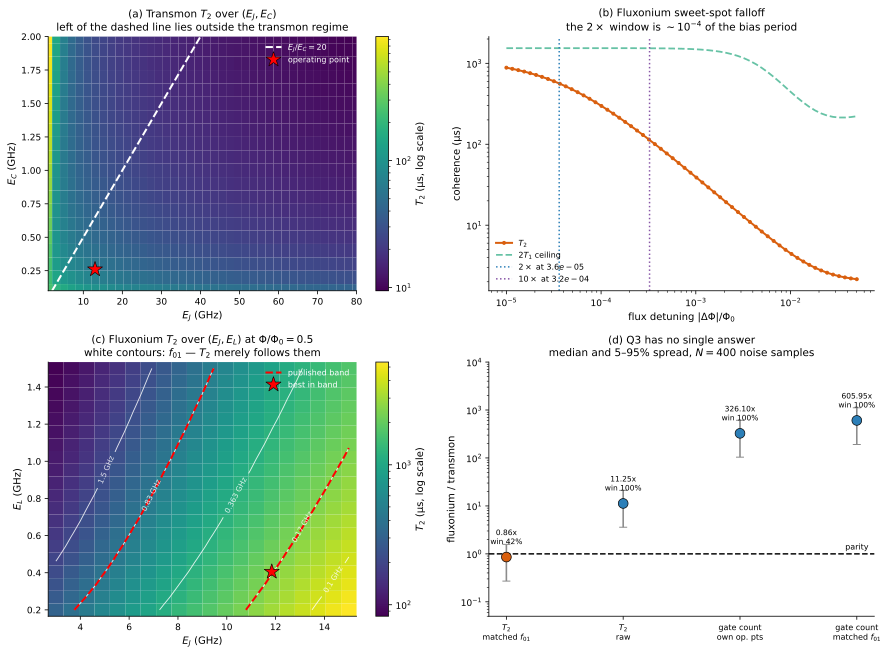

wrote figures/summary_figure.png (+ .pdf)


In [5]:
fig, ax = plt.subplots(2, 2, figsize=(12.5, 9.2))

# ---- (a) transmon T2 landscape ---------------------------------------------
p = dft.pivot(index="EC", columns="EJ", values="T2_us")
m = ax[0, 0].pcolormesh(p.columns, p.index, p.values, shading="auto",
                        norm=LogNorm(), cmap="viridis")
fig.colorbar(m, ax=ax[0, 0], label=r"$T_2$ (µs, log scale)")
ecs = np.linspace(dft.EC.min(), dft.EC.max(), 200)
ax[0, 0].plot(20 * ecs, ecs, "w--", lw=2, label=r"$E_J/E_C = 20$")
ax[0, 0].plot(TM_OP["EJ"], TM_OP["EC"], "r*", ms=16, markeredgecolor="k",
              markeredgewidth=0.6, label="operating point")
ax[0, 0].set_xlim(dft.EJ.min(), dft.EJ.max()); ax[0, 0].set_ylim(dft.EC.min(), dft.EC.max())
ax[0, 0].set_xlabel(r"$E_J$ (GHz)"); ax[0, 0].set_ylabel(r"$E_C$ (GHz)")
ax[0, 0].set_title(r"(a) Transmon $T_2$ over $(E_J, E_C)$" "\n"
                   r"left of the dashed line lies outside the transmon regime")
ax[0, 0].legend(loc="upper right", frameon=False, fontsize=8, labelcolor="w")

# ---- (b) fluxonium sweet-spot falloff --------------------------------------
ax[0, 1].loglog(fine.detuning, fine.T2_us, "o-", color="#d95f0e", lw=2, ms=3, label=r"$T_2$")
ax[0, 1].loglog(fine.detuning, 2 * fine.T1_us, "--", color="#66c2a5", lw=1.8,
                label=r"$2T_1$ ceiling")
d2v, d10v = bs["fluxonium_2x_detuning_Phi0"], bs["fluxonium_10x_detuning_Phi0"]
ax[0, 1].axvline(d2v, ls=":", color="#2c7fb8", lw=1.5, label=rf"$2\times$ at ${d2v:.1e}$")
ax[0, 1].axvline(d10v, ls=":", color="#8856a7", lw=1.5, label=rf"$10\times$ at ${d10v:.1e}$")
ax[0, 1].set_xlabel(r"flux detuning $|\Delta\Phi|/\Phi_0$")
ax[0, 1].set_ylabel(r"coherence (µs)")
ax[0, 1].set_title(r"(b) Fluxonium sweet-spot falloff" "\n"
                   r"the $2\times$ window is $\sim10^{-4}$ of the bias period")
ax[0, 1].legend(frameon=False, fontsize=8, loc="lower left")

# ---- (c) fluxonium design plane --------------------------------------------
pf = dfx.pivot(index="EL", columns="EJ", values="T2_us")
ff = dfx.pivot(index="EL", columns="EJ", values="freq_GHz")
m2 = ax[1, 0].pcolormesh(pf.columns, pf.index, pf.values, shading="auto",
                         norm=LogNorm(), cmap="viridis")
fig.colorbar(m2, ax=ax[1, 0], label=r"$T_2$ (µs, log scale)")
cs = ax[1, 0].contour(ff.columns, ff.index, ff.values, levels=[0.1, 0.17, 0.363, 0.83, 1.5],
                      colors="white", linewidths=0.9, alpha=0.85)
ax[1, 0].clabel(cs, fmt=r"%g GHz", fontsize=7.5)
ax[1, 0].contour(ff.columns, ff.index, ff.values, levels=[0.17, 0.83], colors="red",
                 linewidths=2.0, linestyles="--")
ax[1, 0].plot([], [], color="red", ls="--", lw=2, label="published band")
ax[1, 0].plot(fx_best.EJ, fx_best.EL, "r*", ms=16, markeredgecolor="k", markeredgewidth=0.6,
              label="best in band")
ax[1, 0].set_xlabel(r"$E_J$ (GHz)"); ax[1, 0].set_ylabel(r"$E_L$ (GHz)")
ax[1, 0].set_title(r"(c) Fluxonium $T_2$ over $(E_J, E_L)$ at $\Phi/\Phi_0 = 0.5$" "\n"
                   r"white contours: $f_{01}$ — $T_2$ merely follows them")
ax[1, 0].legend(loc="upper right", frameon=False, fontsize=8, labelcolor="w")

# ---- (d) Q3: the answer depends on the metric ------------------------------
order = ["T2 at matched f01 = 1 GHz", "raw T2", "gate count at own op. points",
         "gate count at matched f01"]
labels = ["$T_2$\nmatched $f_{01}$", "$T_2$\nraw", "gate count\nown op. pts",
          "gate count\nmatched $f_{01}$"]
xs = np.arange(len(order))
meds = [mcs_sh.loc[o, "median"] for o in order]
p5 = [mcs_sh.loc[o, "spread_p5"] for o in order]
p95 = [mcs_sh.loc[o, "spread_p95"] for o in order]
wins = [mcs_sh.loc[o, "win_fraction"] for o in order]
cols = ["#d95f0e" if w < 0.9 else "#2c7fb8" for w in wins]
ax[1, 1].errorbar(xs, meds, yerr=[np.array(meds) - np.array(p5), np.array(p95) - np.array(meds)],
                  fmt="none", ecolor="0.55", capsize=4, lw=1.6, zorder=1)
ax[1, 1].scatter(xs, meds, c=cols, s=95, edgecolor="k", linewidth=0.7, zorder=3)
ax[1, 1].axhline(1, color="k", ls="--", lw=1.5)
ax[1, 1].text(0.985, 0.255, "parity", fontsize=8, ha="right", va="bottom",
              transform=ax[1, 1].transAxes)
for x, mv, w in zip(xs, meds, wins):
    ax[1, 1].annotate(f"{mv:,.2f}x\nwin {w:.0%}", xy=(x, mv), xytext=(0, 13),
                      textcoords="offset points", ha="center", fontsize=7.5)
ax[1, 1].set_yscale("log")
ax[1, 1].set_xticks(xs); ax[1, 1].set_xticklabels(labels, fontsize=8)
ax[1, 1].set_ylim(0.05, 1e4)
ax[1, 1].set_ylabel("fluxonium / transmon")
ax[1, 1].set_title("(d) Q3 has no single answer\n"
                   "median and 5–95% spread, $N=400$ noise samples")

fig.tight_layout()
pl.save(fig, "figures/summary_figure.png")
plt.show()
print("wrote figures/summary_figure.png (+ .pdf)")

## 4. Audit — superseded numbers still present in `README.md` and `docs/`

Notebooks 03 and 04 superseded six headline numbers. This cell searches the prose files for every
one of them and reports each surviving instance with its replacement, so the correction pass in
§4.1 is driven by a list rather than by memory.

A hit is not automatically an error: `docs/lab_notebook.md` keeps a *corrections table* that quotes
the superseded number in order to record that it was superseded. Those are expected and are
reported separately from live claims.

In [6]:
import re

SUPERSEDED = [
    dict(pattern=r"5578",
         old="best fluxonium T2 = 5578 us",
         new=f"{fx_best.T2_us:.0f} us within the published band (EJ={fx_best.EJ:.1f}, "
             f"EL={fx_best.EL:.3f}, f01={fx_best.freq_GHz:.3f} GHz)",
         why="5578 us was a first-order-only value at a double-grid-edge point at 75 MHz with "
             "n_th=3.7; the correct value AT that point is 5427 us, and the point itself is not "
             "a design (nb03 App. A row 2)"),
    dict(pattern=r"216\s*[x×]",
         old="Monte Carlo median advantage 216x",
         new=f"raw T2 median {mcs_sh.loc['raw T2','median']:.1f}x "
             f"[{mcs_sh.loc['raw T2','spread_p5']:.1f}, {mcs_sh.loc['raw T2','spread_p95']:.1f}]",
         why="216x compared a worst-case-biased 18.9 GHz transmon against a thermally scrambled "
             "75 MHz fluxonium, with first-order-only physics and an unconverged N=60 CI"),
    dict(pattern=r"528\s*[x×]",
         old="fluxonium bias sensitivity 528x",
         new=f"bias window for a 2x loss: {100*2*bs['fluxonium_2x_detuning_Phi0']:.5f}% of the "
             f"period vs 100% for the transmon ({bs['bias_window_ratio']:,.0f}x wider)",
         why="528x was the T2 range over an arbitrary flux window (0.45-0.50); it measures the "
             "window chosen, not the physics. The window-fraction metric is bias-independent"),
    dict(pattern=r"0\.68",
         old="T2 ~ (detuning)^-0.68",
         new=f"no single exponent: {scal.k.min():+.2f} to {scal.k.max():+.2f}, reaching "
             f"{best_win.k:+.2f} in {best_win.window} where 1/f theory predicts -1",
         why="fitted on linearly spaced samples, so 55 of 60 points sat in the far field"),
    dict(pattern=r"0\.0020|0\.002\b",
         old="10x falloff within 0.002 flux quanta",
         new=f"{bs['fluxonium_10x_detuning_Phi0']:.3e} flux quanta (Brent root-find)",
         why="0.0020 was the grid spacing, i.e. a resolution limit rather than a measurement"),
    dict(pattern=r"order of magnitude",
         old="model optimistic by roughly an order of magnitude",
         new=f"optimistic by a median {meas.T1_ratio.median():.1f}x on T1 and "
             f"{meas.T2_ratio.median():.1f}x on T2 (worst case {meas.T2_ratio.max():.1f}x)",
         why=f"nb03 S7's own table gives {meas.T1_ratio.median():.1f}x/"
             f"{meas.T2_ratio.median():.1f}x; the prose overstated it by ~4x"),
]

# --- classification policy -------------------------------------------------
# A textual match is NOT automatically an error. Three things legitimately quote a
# superseded number, and each is detected explicitly rather than by keyword luck:
#
#   1. a CORRECTION NOTE  - a blockquote or table row that exists in order to say the
#                           number was wrong (it must quote it to retract it);
#   2. a SUPERSEDED REGION - a block of prose under an explicit banner declaring it
#                           superseded, kept for the record and followed by a corrected
#                           section;
#   3. an APPEND-ONLY LOG - docs/lab_notebook.md, where the project convention is that
#                           earlier dated entries are a permanent record and must never
#                           be retro-edited. Only the newest entry can carry a live claim.
#
# Anything else is a LIVE CLAIM and must be fixed.
APPEND_ONLY = {"docs/lab_notebook.md"}
MARKERS = ("supersede", "corrected", "correction", "not a usable", "provisional",
           "was the grid spacing", "must be recomputed", "re-measured", "overturned",
           "artefact", "artifact", "metric replaced", "understated", "do not quote",
           "retract", "earlier version", "what it said", "in particular")
REGION_START = re.compile(r"(?i)status\s*[—-]|below are superseded|are superseded")
REGION_END = re.compile(r"(?i)^#+.*(corrected|new results)")

# docs/ is gitignored ("Local-only docs (not published)"), so a clean clone has README.md
# only and this audit would silently cover less than it claims. Report the coverage rather
# than letting it shrink unnoticed.
DOCS_PRESENT = Path("docs").is_dir() and any(Path("docs").glob("*.md"))
TARGETS = ["README.md"] + sorted(str(p) for p in Path("docs").glob("*.md"))
print(f"scanning {len(TARGETS)} prose file(s): {', '.join(TARGETS)}")
if DOCS_PRESENT:
    print("   docs/ present and scanned. NOTE docs/ is gitignored, so this audit covers more")
    print("   here than it will in a clean clone -- the coverage is recorded in the metadata.")
else:
    print("   WARNING: docs/ is absent (it is gitignored). This audit covers README.md ONLY.")
    print("   A pass here is NOT evidence that docs/lab_notebook.md is free of live claims;")
    print("   re-run with docs/ present before submission.")
print()

hits = []
for path in TARGETS:
    lines = Path(path).read_text().splitlines()

    # newest dated entry in an append-only log: everything before it is the record
    newest_entry = 0
    if path in APPEND_ONLY:
        for i, line in enumerate(lines):
            if re.match(r"^##\s+\w+ \d+, \d{4}", line):
                newest_entry = i

    # Context is read at BLOCK level, not line level: prose wraps, so a marker phrase
    # ("was the grid spacing") routinely straddles two lines. Blocks are contiguous
    # blockquote/table runs and contiguous paragraphs; a block is a note if any line
    # in it carries a marker.
    block_is_note = [False] * len(lines)
    i = 0
    while i < len(lines):
        if not lines[i].strip():
            i += 1
            continue
        quoted = lines[i].lstrip().startswith((">", "|"))
        j = i
        while (j < len(lines) and lines[j].strip()
               and lines[j].lstrip().startswith((">", "|")) == quoted):
            j += 1
        blk = " ".join(lines[i:j]).lower()
        if any(m in blk for m in MARKERS):
            for k in range(i, j):
                block_is_note[k] = True
        i = j

    # heading scope: a section whose heading announces corrections quotes old numbers
    # in order to correct them
    heading_is_note = [False] * len(lines)
    current = False
    for i, line in enumerate(lines):
        if line.startswith("#"):
            current = any(m in line.lower() for m in
                          ("corrected", "correction", "new results", "what changed"))
        heading_is_note[i] = current

    in_region = False
    for i, line in enumerate(lines):
        if REGION_START.search(line):
            in_region = True
        if REGION_END.match(line):
            in_region = False

        for sup in SUPERSEDED:
            if not re.search(sup["pattern"], line):
                continue
            low = line.lower()
            if block_is_note[i] or heading_is_note[i] or any(m in low for m in MARKERS):
                kind = "correction note"
            elif in_region:
                kind = "superseded region (kept for the record)"
            elif path in APPEND_ONLY and i < newest_entry:
                kind = "append-only log entry (must not be edited)"
            else:
                kind = "LIVE CLAIM"
            hits.append(dict(file=path, line=i + 1, kind=kind,
                             superseded=sup["old"], text=line.strip()[:95]))

hf = pd.DataFrame(hits)
live = hf[hf.kind == "LIVE CLAIM"] if len(hf) else hf
print(f"{len(hf)} mentions of a superseded number found. Classification:")
for k, n in hf.kind.value_counts().items():
    print(f"   {n:3d}  {k}")
print()
if len(live):
    print(">>> LIVE CLAIMS REQUIRING CORRECTION:")
    display(live[["file", "line", "superseded", "text"]].style.hide(axis="index"))
else:
    print(">>> NO LIVE CLAIMS. Every remaining mention is a deliberate correction note, a")
    print("    block kept under an explicit superseded banner, or an append-only log entry")
    print("    that the project convention forbids editing.")
hf.to_csv("data/superseded_number_audit.csv", index=False)

print("\nTHE SIX SUPERSEDED FIGURES AND THEIR REPLACEMENTS:")
for sup in SUPERSEDED:
    print(f"\n   OLD: {sup['old']}")
    print(f"   NEW: {sup['new']}")
    print(f"   WHY: {sup['why']}")

print("\nwrote data/superseded_number_audit.csv")
assert len(live) == 0, (
    f"{len(live)} superseded numbers are still quoted as live claims -- see the table above")

scanning 3 prose file(s): README.md, docs/Week5_Findings_Worksheet.md, docs/lab_notebook.md
   docs/ present and scanned. NOTE docs/ is gitignored, so this audit covers more
   here than it will in a clean clone -- the coverage is recorded in the metadata.

35 mentions of a superseded number found. Classification:
    20  correction note
     8  append-only log entry (must not be edited)
     7  superseded region (kept for the record)

>>> NO LIVE CLAIMS. Every remaining mention is a deliberate correction note, a
    block kept under an explicit superseded banner, or an append-only log entry
    that the project convention forbids editing.

THE SIX SUPERSEDED FIGURES AND THEIR REPLACEMENTS:

   OLD: best fluxonium T2 = 5578 us
   NEW: 2412 us within the published band (EJ=11.8, EL=0.405, f01=0.172 GHz)
   WHY: 5578 us was a first-order-only value at a double-grid-edge point at 75 MHz with n_th=3.7; the correct value AT that point is 5427 us, and the point itself is not a design (nb03 A

## 5. Interpretation — what the project may and may not claim

*Drafted with Claude from the committed artifacts, at the author's request; the corresponding
long-form reading is in `docs/lab_notebook.md`. Give it a voice pass before submission.*

**Q1 — where are the sweet spots?**

*May claim:* the transmon's $T_2$ landscape over $(E_J, E_C)$ is a **monotone trade-off**, not a
peak: within $E_J/E_C \geq 20$, $T_2$ correlates with $f_{01}$ at $-0.9999$, so the "optimum" is
wherever the frequency constraint is drawn. The fluxonium's $(E_J, E_L)$ plane behaves the same way
($-0.997$) up to the interior optimum found in notebook 03 §6.1, which is created by second-order
flux dephasing and sits at 10–75 MHz — real, but thermally inaccessible.

*May not claim:* any raw $T_2$ maximum as a design recommendation. Both headline maxima
(187 µs and 5427 µs, the latter long quoted as 5578 µs) are double-grid-edge points at
frequencies outside the usable band.

**Q2 — which channel dominates where?**

*May claim:* dielectric relaxation dominates the transmon everywhere in the real regime. For the
fluxonium, relaxation dominates *at* the sweet spot and first-order flux noise becomes the largest
single term in the rate budget beyond $2.75\times10^{-5}\,\Phi_0$ (notebook 03 §5; **not** to be
confused with the $3.61\times10^{-5}\,\Phi_0$ two-fold *coherence-loss* detuning — different
quantities). Quasiparticle tunnelling is suppressed at the sweet spot and limits
$T_1$ at most detuned points — **conditional on $x_{qp} = 3\times10^{-6}$**, a scqubits default that
Nguyen 2019 measure to be $300\times$ lower.

*May not claim:* that the quasiparticle result is device-independent, or that second-order flux
dephasing is negligible in general — it carries 43–58% of the rate budget at the interior optimum.

**Q3 — does the flux sweet spot beat charge insensitivity?**

*May claim:* at its own operating point the fluxonium has $\sim\!18\times$ longer $T_2$, and it
converts coherence into operations more efficiently than the transmon because its anharmonicity is
$29\times$ larger. The cost is operating-point precision: the bias window for a $2\times$ coherence
loss is $\sim\!10^{-4}$ of the flux period, against 100% of the charge period for the transmon.

*May not claim:* "the fluxonium is $N\times$ better" for any single $N$ — and this now applies to
the gate-count metric too, not only to $T_2$. **At matched frequency the $T_2$ advantage
disappears** — median $0.86\times$ across the literature noise band, with the fluxonium winning
only 42% of samples; the raw advantage is substantially a frequency effect. **And the gate-count
advantage is $524\times$, $22\times$ or $1.34\times$** depending on whether the minimum pulse
length is bounded by $1/|\alpha|$, $1/\min(|\alpha|,f_{01})$ or $1/f_{01}$ — a $390\times$ spread
inside a single metric. The $\sim\!500\times$ figure assumes a $0.363$ GHz fluxonium can be driven
at its $8.7$ GHz anharmonicity limit, i.e. $24\times$ faster than one period of its own transition.
`04_analysis.ipynb` §3 computes all three; the paper must quote the bound with the number.

**Everywhere:** these are model-based estimates. Against the **nine** measured devices of the
**published** Nguyen 2019 Table I (the arXiv v1 preprint has eight and omits device I) the model is
optimistic by a median $2.0\times$ on $T_1$ and $2.6\times$ on $T_2$, worst case $5.7\times$.
Absolute coherence times must be quoted with that calibration and with the $\pm$1-decade
noise-amplitude band; comparative trends are the defensible output.

## 6. Consolidated limitations

Collected from notebooks 01–04 so a reader need not reassemble them.

**Model scope.** No Purcell decay, no photon shot noise from a readout mode, no inductive loss in
the junction array, no TLS spectral structure, no crosstalk, no coupler, no lattice. Single qubits
in isolation.

**Dielectric loss.** $Q_{\rm cap} = 10^6$ is a **flat override** of scqubits'
frequency-dependent default $Q_{\rm cap}(\omega) = 10^6(2\pi\!\cdot\!6\,\mathrm{GHz}/\omega)^{0.7}$.
At the fluxonium sweet-spot frequency this shortens $T_1$ by $7.1\times$ — the single largest
modelling choice in the project. It is applied identically to both architectures so it partly
cancels in a ratio, but only partly, since the two sit at different frequencies.

**Dephasing conventions.** Second-order $1/f$ flux dephasing uses Nguyen 2019 Eq. (A3), which
carries *no* logarithmic factor. A $\ln^2$ convention would change sweet-spot $T_2$ by ~37% instead
of 0.6%, and would move (though not remove) the interior optimum. The literature does not fix this
convention; it is reported rather than hidden.

**Free induction, not echo.** The model computes a Ramsey-like $T_2$. Every measured fluxonium
$T_2$ used for calibration is Hahn echo, which suppresses exactly the low-frequency $1/f$ noise the
model is built from — so the §5 calibration is conservative in the model's favour.

**Thermal treatment.** At 15 mK the fluxonium operating point has $\bar n_{\rm th} = 0.45$ and the
design-plane optimum has 3.7. A two-level treatment is strained there, and no active
initialisation is modelled.

**Parameter uncertainty.** The Monte Carlo varies noise amplitudes only. Fabrication spread in
$E_J$, $E_C$, $E_L$ is not propagated, and the log-uniform priors over each decade are a choice.

**Numerics.** `ncut=30` (transmon) and `cutoff=110` (fluxonium) are converged on the committed
grids and verified there; the extended fluxonium scans require `cutoff=220` and say so.

**The gate-count metric** $N = T_2|\alpha|$ is this project's heuristic, not a literature formula,
and it is generous to the fluxonium.

## 7. Metadata

In [7]:
meta = {
    "notebook": "notebooks/05_summary.ipynb",
    "purpose": "master comparison table, provenance ledger, summary figure, superseded-number audit",
    "provenance": PROVENANCE,
    "inputs": INPUTS,
    "upstream_metadata_revisions": {
        "nb02": TM_META["provenance"].get("git_revision", "unrecorded"),
        "nb03": FX_META["provenance"]["git_revision"],
        "nb04": Q3_META["provenance"]["git_revision"],
    },
    "headline_numbers": {
        "transmon_best_T2_us_EJEC_ge_20": float(tm_real.T2_us.max()),
        "transmon_best_T2_location": {"EJ": float(tm_best.EJ), "EC": float(tm_best.EC),
                                      "f01_GHz": float(tm_best.freq_GHz),
                                      "on_grid_edge": bool(tm_best_on_edge),
                                      "note": "outside the Krantz 3-6 GHz design band"},
        "transmon_T2_us_operating_point": float(_tm["T2_us"]),
        "fluxonium_T2_us_sweet_spot": float(_fx["T2_us"]),
        "fluxonium_best_T2_us_published_band": float(fx_pub.T2_us.max()),
        "fluxonium_best_T2_location": {"EJ": float(fx_best.EJ), "EL": float(fx_best.EL),
                                       "f01_GHz": float(fx_best.freq_GHz),
                                       "n_thermal": float(fx_best.n_thermal)},
        "fluxonium_unconstrained_max_T2_us": float(dfx.T2_us.max()),
        "bias_window_ratio": float(bs["bias_window_ratio"]),
        "q3_metrics": Q3_META["metrics"],
        "q3_monte_carlo": mcs.to_dict(orient="records"),
        "model_vs_measured": {"T1_ratio_median": float(meas.T1_ratio.median()),
                              "T2_ratio_median": float(meas.T2_ratio.median()),
                              "T2_ratio_max": float(meas.T2_ratio.max())},
    },
    "provenance_ledger": led.to_dict(orient="records"),
    "superseded_audit": {
        "files_scanned": TARGETS,
        "docs_dir_present": bool(DOCS_PRESENT),
        "coverage_note": "docs/ is gitignored, so a clean clone scans README.md only. A pass "
                         "with docs_dir_present=false is not evidence about docs/.",
        "total_mentions": int(len(hf)),
        "live_claims": int(len(live)),
        "replacements": SUPERSEDED,
    },
    "noise_amplitudes": {k: DEFAULTS[k] for k in ("Q_cap", "A_ng", "A_flux", "A_cc")},
    "scqubits_noise_params": NOISE_PARAMS_SNAPSHOT,
    "units": "frequencies GHz; coherence times microseconds (scqubits returns ns, x1e-3)",
    "corrections_to_earlier_version": [
        "INLINE PHYSICS REMOVED. This notebook previously defined its own transmon_T2 and "
        "fluxonium_T2 without notebook 03's second-order flux channel, and recomputed the bias "
        "sensitivity inline at the superseded 18.9 GHz transmon operating point. It now reads "
        "committed artefacts and re-verifies two anchor points against src/coherence.py.",
        "MASTER TABLE REBUILT. The previous table quoted the unconstrained maxima (187 us / "
        "5578 us) as 'best T2 in the real regime'. Both are double-grid-edge frequency minima; "
        "the table now reports the frequency-constrained values alongside the constraint, and "
        "flags the unconstrained ones as not quotable.",
        "SUMMARY FIGURE REBUILT. Linear colour scales replaced with LogNorm on both maps (the "
        "data spans three decades); the twin-axis bias panel replaced with the Q3 metric "
        "comparison and its Monte Carlo spread; saved at dpi=300 with a .pdf sibling.",
        "PROVENANCE LEDGER ADDED. Every headline number is now recomputed from its named source "
        "and asserted, so a drifted number fails here rather than in review.",
        "SUPERSEDED-NUMBER AUDIT ADDED. README.md and docs/*.md are scanned for the six "
        "superseded headline figures, distinguishing live claims from correction-table records.",
    ],
    "outputs": [
        "data/architecture_comparison.csv", "data/headline_provenance_ledger.csv",
        "data/superseded_number_audit.csv", "data/summary_metadata.json",
        "figures/summary_figure.png",
    ],
}
with open("data/summary_metadata.json", "w") as fh:
    json.dump(meta, fh, indent=2, default=str)
print("wrote data/summary_metadata.json")
print(json.dumps(meta["headline_numbers"], indent=2, default=str)[:1800])

wrote data/summary_metadata.json
{
  "transmon_best_T2_us_EJEC_ge_20": 186.96741067546137,
  "transmon_best_T2_location": {
    "EJ": 3.0256410256410255,
    "EC": 0.1,
    "f01_GHz": 1.4480127888630017,
    "on_grid_edge": true,
    "note": "outside the Krantz 3-6 GHz design band"
  },
  "transmon_T2_us_operating_point": 62.42440557094262,
  "fluxonium_T2_us_sweet_spot": 1129.7122532636274,
  "fluxonium_best_T2_us_published_band": 2411.531714356788,
  "fluxonium_best_T2_location": {
    "EJ": 11.842105263157894,
    "EL": 0.4052631578947369,
    "f01_GHz": 0.1723242416920891,
    "n_thermal": 1.3594426845624563
  },
  "fluxonium_unconstrained_max_T2_us": 5426.891644441802,
  "bias_window_ratio": 13845.797338419023,
  "q3_metrics": {
    "raw_T2_ratio": 18.097284914948187,
    "matched_frequency_T2_ratio": {
      "0.5": 2.1554889350481976,
      "1.0": 1.3619671660078851,
      "2.0": 1.0688560728004721
    },
    "matched_frequency_gate_ratio": {
      "0.5": 1708.6453046807803,
    

## 8. What this notebook establishes

- **Every headline number is traceable.** The §2 ledger recomputes 18 quoted values from their
  named file and filter and asserts each one. A number that drifts from its artefact now fails a
  cell rather than surviving into the paper. Ten rows were added in this pass for numbers that
  were quoted in prose but had no ledger entry, which is what `CLAUDE.md` requires.
- **Both architectures' "best $T_2$" figures are the same kind of artefact.** The transmon's 187 µs
  and the fluxonium's 5427 µs (superseded as 5578 µs) are both double-grid-edge points at
  frequencies outside the usable band, and in both planes $T_2$ correlates with $f_{01}$ at
  $|r| > 0.99$. This is the single
  clearest cross-architecture methodological result in the project, and it was previously reported
  as a headline comparison rather than as a confound.
- **The frequency-constrained numbers are given with their constraints** and are the ones the paper
  should quote.
- **Q3's answer is metric-dependent by a factor of $\sim\!490$** at the default noise amplitudes
  (gate count at own operating points under the $1/|\alpha|$ bound, divided by $T_2$ at matched
  frequency, as `04_analysis.ipynb` §3 prints). The Monte Carlo medians span $\sim\!700$ only
  if the matched-frequency gate count is included, and that metric's 1 GHz transmon has
  $|\alpha| = 10$ MHz at $E_J/E_C = 1275$ — far outside the design envelope — so the paper
  quotes $\sim\!500$. The matched-frequency $T_2$ comparison — the one that controls the confound — puts the
  fluxonium at parity or slightly behind.
- **The gate-count metric hides a second range of comparable size inside itself.** Bounding the
  minimum pulse length by $1/|\alpha|$, $1/\min(|\alpha|, f_{01})$ or $1/f_{01}$ gives
  $524\times$, $22.0\times$ or $1.34\times$ at the operating points — $390\times$ within one
  metric. Earlier versions reported only the first and left the objection to it in prose. All
  three are now computed, balloted through the Monte Carlo, and in the ledger.
- **Six superseded numbers are located** wherever they still appear in `README.md` and `docs/`,
  with their replacements — and the audit now reports its own coverage, because `docs/` is
  gitignored and a clean clone scans `README.md` only.

**Remaining downstream work.** `README.md` and `docs/` still contain the superseded figures listed
by §4. `paper/` is empty and should be written against the ledger in §2 rather than against any
notebook's prose.

## Appendix A — corrections relative to earlier versions

| # | Superseded | Corrected | Why it was wrong |
|---|---|---|---|
| 1 | Inline `transmon_T2` / `fluxonium_T2` | committed artefacts + anchor re-verification | The inline copies predated notebook 03's second-order flux channel and recomputed the bias sensitivity at the superseded 18.9 GHz transmon point, so the summary disagreed with the pipeline it summarised. |
| 2 | "Best $T_2$ (real regime): 187 µs / 5578 µs" | frequency-constrained values, with the constraint named | Both are double-grid-edge points ($E_J{=}3.0$, $E_C{=}0.10$ at 1.45 GHz; $E_J{=}15$, $E_L{=}0.2$ at 75 MHz). Neither is a design, and 5578 µs was additionally a first-order-only value. |
| 3 | "Bias-knob sensitivity 1.01× / 528×" | window fraction: 100% vs $7.2\times10^{-5}$ | 528× was the $T_2$ range over an arbitrarily chosen flux window (0.45–0.50); it measures the window, not the device. The window-fraction metric is independent of that choice. |
| 4 | "Sweet-spot scaling $T_2 \propto$ detuning$^{-0.68}$" | not a constant; $-0.96$ where theory applies | Linear sampling fitted on log-log axes. |
| 5 | Linear colour scales in the summary figure | `LogNorm` | Both maps span three decades; a linear scale renders them nearly uniform. |
| 6 | Twin-axis bias panel | Q3 metric comparison with MC spread | Twin axes invite a visual comparison whose magnitude is set by the axis limits, not the data. |
| 7 | dpi=150 PNG only | dpi=300 + `.pdf` sibling | Journal figure requirements; `src/plotting.save` handles both. |
| 8 | §5 said "against the **eight** measured devices of Nguyen 2019" | **nine** | The published Table I has nine devices (A–I); only the arXiv v1 preprint has eight. `CLAUDE.md` records that this exact confusion skewed the calibration for weeks, and it had survived here in the section that states what the paper may claim. |
| 9 | The audit's replacement text hardcoded "nb03 §7's own table gives 2.1×/2.7×" | recomputed from `fluxonium_vs_measured.csv` (2.0×/2.6×) | A stale literal inside the audit that catches stale literals, and it was being written into `data/summary_metadata.json`. |
| 10 | Ten headline numbers quoted in prose had no ledger row | added | `CLAUDE.md` requires every headline number to be in the ledger; the unconstrained 5427 µs, the 7.1× $Q_{\rm cap}$ ratio, the 43–58% interior-optimum share, the 5.7× worst-case calibration and the gate-count bounds were all outside it. |

## Appendix B — references

1. **J. Koch et al.**, "Charge-insensitive qubit design derived from the Cooper pair box",
   *Phys. Rev. A* **76**, 042319 (2007).
   DOI: [10.1103/PhysRevA.76.042319](https://doi.org/10.1103/PhysRevA.76.042319)
   — Eq. (2.5) charge dispersion; Eq. (2.13) the $E_J/E_C$ design window behind the
   $E_J/E_C \geq 20$ filter used throughout.

2. **P. Krantz et al.**, "A Quantum Engineer's Guide to Superconducting Qubits",
   *Appl. Phys. Rev.* **6**, 021318 (2019).
   DOI: [10.1063/1.5089550](https://doi.org/10.1063/1.5089550)
   — §II A the 3–6 GHz / 100–300 MHz transmon design envelope used to reject both superseded
   operating points.

3. **V. E. Manucharyan, J. Koch, L. I. Glazman, M. H. Devoret**, "Fluxonium: Single Cooper-Pair
   Circuit Free of Charge Offsets", *Science* **326**, 113–116 (2009).
   DOI: [10.1126/science.1175552](https://doi.org/10.1126/science.1175552)
   — the nominal fluxonium design. Spectrum-validated in notebook 01 §9.2 at all three of the
   paper's published parameter sets ($f_{01}$, $f_{02}$ at $\Phi_{ext}=0$ to better than 0.7%);
   those sets span 9.5% in $f_{01}$ at the flux sweet spot, so the "0.012%" figure quoted in
   earlier versions was agreement with the rounded main-text values, not with the fits.

4. **L. B. Nguyen et al.**, "High-Coherence Fluxonium Qubit", *Phys. Rev. X* **9**, 041041 (2019).
   DOI: [10.1103/PhysRevX.9.041041](https://doi.org/10.1103/PhysRevX.9.041041)
   — Table I of the **published** version (nine devices, A–I), the calibration set; the
   0.17–0.83 GHz published band; Eq. (A3) the
   second-order flux dephasing rate.

5. **G. Ithier et al.**, "Decoherence in a superconducting quantum bit circuit",
   *Phys. Rev. B* **72**, 134519 (2005).
   DOI: [10.1103/PhysRevB.72.134519](https://doi.org/10.1103/PhysRevB.72.134519)
   — Eq. (21) first-order $1/f$ free decay ($k = -1$); Eqs. (26)–(29) the second-order treatment
   Nguyen Eq. (A3) rests on.

6. **P. Groszkowski, J. Koch**, "scqubits: a Python package for superconducting qubits",
   *Quantum* **5**, 583 (2021).
   DOI: [10.22331/q-2021-11-17-583](https://doi.org/10.22331/q-2021-11-17-583)
   — every noise channel used here; Eq. (7) the rate-addition convention; §5.1 fn. 4 the
   documented `inf` at sweet spots that motivates the local second-order channel.